<a href="https://colab.research.google.com/github/Azi-Lizzy/ii-dlsca/blob/main/03_Regularizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 3: Regularization Techniques

In this exercise, you will learn how to add regularization to a neural network and explore how regularization related hyperparameters affect the model performance. We will focus on three techniques: **$L_1$ regularization, $L_2$ regularization, and dropout**. We use multilayer perceptrons (MLPs) to make the architectural changes easy to follow.

You will work with traces collected from an unprotected software implementation of Ascon and investigate whether suitable regularization settings can improve the performance of a deep learning-based side-channel attack (DL-SCA).

The exercise consists of four steps:

**Train and evaluate a baseline model:** Build and train an MLP without explicit regularization. Use its predictions for the attack traces to recover a single key byte and calculate the guessing entropy (GE) and the required number of attack traces (NT).

**Apply $L_1$ regularization:** Add $L_1$ regularization to the model and experiment with different values of the regularization strength, $\lambda$. Compare the attack performance with that of the baseline model.

**Apply $L_2$ regularization:** Repeat the experiment using $L_2$ regularization. Tune $\lambda$ for $L_2$ and compare the attack performance with that of the baseline model.

**Apply dropout:** Add dropout to the model and experiment with different dropout rates. Compare the attack performance with that of the baseline model.

For a fair comparison, we should train each variant from the same initial weights and keep the data split and other training settings unchanged. For that you should use a fixed seed for rando values generation.

## Environment Preparations

Let’s start by setting up your Google Colab environment.

Run the cell below by clicking the ▶ button or pressing Shift + Enter. It installs the libraries needed for this exercise. Wait until the installation finishes before moving to the next cell.

You only need to run this installation once per Colab runtime session.

In [ ]:
!pip install numpy
!pip install h5py
!pip install trsfile
!pip install tensorflow==2.22.0rc0

^C
Traceback (most recent call last):
  File "/mnt/d/.tf/bin/pip", line 8, in <module>
    sys.exit(main())
  File "/mnt/d/.tf/lib/python3.14/site-packages/pip/_internal/cli/main.py", line 77, in main
    command = create_command(cmd_name, isolated=("--isolated" in cmd_args))
  File "/mnt/d/.tf/lib/python3.14/site-packages/pip/_internal/commands/__init__.py", line 119, in create_command
    module = importlib.import_module(module_path)
  File "/usr/lib/python3.14/importlib/__init__.py", line 88, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
  File "<frozen importlib._bootstrap>", line 1406, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1371, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1342, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 938, in _load_unlocked
  File "<frozen importlib._bootstrap_external>", line 755, in exec_module
  File "<frozen importlib._bootstrap_external>", line 851, in g

## Download the dataset and the models

Next, download the nopoi-ASCAD dataset and pretrained models used in this exercise.

Run the cell below to download the files from Zenodo into your Colab environment. Wait until the download finishes before continuing.

You only need to run this cell once per Colab runtime session. The downloaded files and folders will be stored in /content/. You can find them by clicking the folder icon in Colab’s left sidebar.

In [ ]:
!wget https://zenodo.org/records/23102432/files/03_Regularizations.zip?download=1 -O 03_Regularizations.zip
!unzip 03_Regularizations.zip
!rm 03_Regularizations.zip

## Load the Dataset

Next, we load the dataset. It contains power traces from a **32-bit optimized implementation of unprotected Ascon-128 v1.2**. The traces were collected using a ChipWhisperer-Lite board and an oscilloscope with 8-bit resolution. They capture the **first permutation round during Ascon’s initialization phase**, with **772 power samples per trace**.

Each trace also includes the **16-byte key** used for that encryption and the **16-byte public nonce**, which changes with each new encryption. The nonce is stored as two 8-byte parts: `nonce0` and `nonce1`.

**Run the cell below** to load the dataset. For more information about its structure, see the [dataset description on Zenodo](https://zenodo.org/records/10229484).

In [2]:
import numpy as np
import trsfile

IV = np.array([128, 64, 12, 6, 0, 0, 0, 0], dtype=np.uint8)
HW = np.array([int(i).bit_count() for i in range(256)], dtype=np.uint8)

# Dataset settings: edit the path for your computer.
dataset_file = "/mnt/d/Workshops/CHES_Tutorial/Data_base/03_Regularizations/Ascon_Unprotected.trs"
n_profiling = 50000
n_attack = 5000
number_of_samples = 772
target_byte = 3                 # 0..7, in the first key word
leakage_model = 'SB-8'          # 'SB-8' (256 classes) or 'HW' (9 classes). For Ascon SB-8 is equivalent to ID

assert 0 <= target_byte < 8
assert leakage_model in ('SB-8', 'HW')

# Read the profiling and attack blocks.
n_total = n_profiling + n_attack
samples = np.zeros((n_total, number_of_samples), dtype=np.float64)
nonces = np.zeros((n_total, 16), dtype=np.uint8)
keys = np.zeros((n_total, 16), dtype=np.uint8)

with trsfile.open(dataset_file, 'r') as traces:
    for i in range(n_total):
        trace = traces[i]
        samples[i] = trace.samples
        keys[i] = np.frombuffer(bytes(trace.parameters['key'].value), dtype=np.uint8)
        nonces[i, :8] = np.frombuffer(bytes(trace.parameters['nonce0'].value), dtype=np.uint8)
        nonces[i, 8:] = np.frombuffer(bytes(trace.parameters['nonce1'].value), dtype=np.uint8)

# We break the keys and nonces into two 8-byte halves, to match state of the Ascon and its implementation.
key0 = keys[:, 0:8]
key1 = keys[:, 8:16]
nonces0 = nonces[:, 0:8]
nonces1 = nonces[:, 8:16]

intermediate = nonces0[:,target_byte] ^ nonces1[:,target_byte] ^ (IV[target_byte] & key0[:,target_byte]) ^ (nonces1[:,target_byte] & key0[:,target_byte]) ^ key0[:,target_byte]
y_4 = HW[intermediate] if leakage_model == "HW" else intermediate

X_profiling = samples[:n_profiling]
Y_profiling = y_4[:n_profiling]
X_attack = samples[n_profiling:]

# Profiling data 
profiling_data = np.zeros((n_profiling, 4), dtype=np.uint8)
profiling_data[:, 0] = key0[:n_profiling, target_byte]
profiling_data[:, 1] = key1[:n_profiling, target_byte]
profiling_data[:, 2] = nonces0[:n_profiling, target_byte]
profiling_data[:, 3] = nonces1[:n_profiling, target_byte]


# Attack data
attack_data = np.zeros((n_attack, 4), dtype=np.uint8)
attack_data[:, 0] = key0[n_profiling:, target_byte]
attack_data[:, 1] = key1[n_profiling:, target_byte]
attack_data[:, 2] = nonces0[n_profiling:, target_byte]
attack_data[:, 3] = nonces1[n_profiling:, target_byte]

good_key = int(attack_data[0, 0])
assert np.all(attack_data[:, 0] == good_key), 'The attacked key byte must be fixed.'

print('Profiling traces shape:', X_profiling.shape)
print('Profiling labels shape:', Y_profiling.shape)
print('Attack traces shape:', X_attack.shape)


Profiling traces shape: (50000, 772)
Profiling labels shape: (50000,)
Attack traces shape: (5000, 772)


## Train and Evaluate a Baseline Model

In this exercise you first build and train a baseline MLP without explicit regularization. By baseline we mean a model that does not use any reqularization techniques like $L_1, L_2$ or $Dropout$. This model gives us an idea about how the results look like when we are relying on the implicit regularization of gradiant dicent. 

Then you use that model's predictions for the attack traces to recover a single key byte and calculate the GE and the **required number of attack traces (NT)**. Tis metric has been introduced during the presentation. to remember it you can look at the following section.

In this exercise, you will first build and train a **baseline MLP** without any explicit regularization.

By *baseline*, we mean a model that does not use regularization techniques such as $L_1$, $L_2$, or Dropout. This allows us to observe the model's behavior when relying only on the **implicit regularization introduced by the optimization process**, such as stochastic gradient descent and its variants.

After training the model, you will use its predictions on the attack traces to recover a single key byte and evaluate the attack using GE and the **required Number of attack Traces (NT)**.





### Exercise:
### Build and train the baseline model
Complete the missing code in the `create_model()` function using the following hyperparameters:

```python
{
    "activation": "elu",
    "kernel_initializer": "glorot_uniform",
    "layers": 4,
    "neurons": 200,
}
```

The missing code should define:
- The input layer.
- The hidden Dense layers.
- The output layer.

The profiling traces `X_profiling` and their corresponding labels `Y_profiling` were already loaded and generated in the previous section.

Before completing the model, consider the following questions:
- Based on the number of samples in each trace, what should the input shape of the model be?
- The targeted intermediate value is still $y_4$, the fifth word after the S-box layer of the first Ascon permutation round. The labels are generated using the SB-8 leakage model. How many output classes should the model therefore have?

Complete the missing code in the training section to train the baseline model using X_profiling and Y_profiling.

In [ ]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import *
from tensorflow.keras import backend as K
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import *

import gc
from pathlib import Path

batch_size = 128
epochs = 15

for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # The GPU may already be initialized if this cell is rerun.

def create_model(input_length):
    tf.keras.utils.set_random_seed(929735)

    inputs = Input(shape=(input_length,))
    x = BatchNormalization()(inputs)

    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)

    outputs_layer = Dense(256, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs_layer)

    model.compile(
        optimizer=Adam(learning_rate=0.0009969971601608608),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    model.summary()
    return model


model = create_model(X_profiling.shape[1])

history = model.fit(X_profiling, 
                        Y_profiling,
                        validation_split=0.15,
                        epochs=epochs, 
                        batch_size=batch_size, 
                        verbose=2)

I0000 00:00:1791579770.682111    1616 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791579774.487456    1616 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791579861.542292    1616 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1791579941.314032    1616 gpu_device.cc:2318] TensorFlow was not built with CUDA kernel binar

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 772)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 772)            │         3,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       154,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 200)            │        40,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        51,456 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329,744 (1.26 MB)

 Trainable params: 328,200 (1.25 MB)

 Non-trainable params: 1,544 (6.03 KB)

Epoch 1/15


I0000 00:00:1791579950.227335    1616 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791579950.743338    1616 se_gpu_pjrt_compiler.cc:274] Found GPU target config and a PjRtClient with matching configuration. Performing a JIT compilation.
I0000 00:00:1791579952.773264    2227 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791579954.151029    2221 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791579955.038076    2224 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791579955.719812    2232 subprocess_compilation.cc:349] ptxas warning : Re

333/333 - 47s - 141ms/step - accuracy: 0.0097 - loss: 5.4010 - val_accuracy: 0.0039 - val_loss: 5.8807
Epoch 2/15
333/333 - 4s - 13ms/step - accuracy: 0.0244 - loss: 4.9692 - val_accuracy: 0.0239 - val_loss: 4.9366
Epoch 3/15
333/333 - 5s - 14ms/step - accuracy: 0.0354 - loss: 4.7772 - val_accuracy: 0.0244 - val_loss: 4.9994
Epoch 4/15
333/333 - 5s - 14ms/step - accuracy: 0.0462 - loss: 4.6631 - val_accuracy: 0.0299 - val_loss: 4.9187
Epoch 5/15
333/333 - 5s - 15ms/step - accuracy: 0.0570 - loss: 4.5466 - val_accuracy: 0.0289 - val_loss: 4.9591
Epoch 6/15
333/333 - 5s - 15ms/step - accuracy: 0.0689 - loss: 4.4334 - val_accuracy: 0.0272 - val_loss: 5.0428
Epoch 7/15
333/333 - 5s - 15ms/step - accuracy: 0.0819 - loss: 4.3201 - val_accuracy: 0.0245 - val_loss: 5.1587
Epoch 8/15
333/333 - 5s - 14ms/step - accuracy: 0.0953 - loss: 4.2046 - val_accuracy: 0.0243 - val_loss: 5.2538
Epoch 9/15
333/333 - 4s - 13ms/step - accuracy: 0.1102 - loss: 4.0867 - val_accuracy: 0.0232 - val_loss: 5.3625
E

### Attack and report NT
After training the model, use it to predict class probabilities for the attack traces. The GE is calculated in the same way as in the previous exercises. In this exercise, however, we go one step further and also calculate the **Number of attack Traces (NT)**.

NT is another metric used to evaluate the efficiency of a DL-SCA attack. It indicates how many attack traces are required for the correct key hypothesis to reach **GE = 1**. In other words, NT is the first trace index at which the average rank of the correct key becomes 1.

To calculate NT, we therefore examine the GE evolution and determine the first number of attack traces for which $GE=1$. 

Fill in the missing code for calculating NT.


17/40 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

W0000 00:00:1791582605.216885    1616 prefetch_dataset_op.cc:478] SEVERE STARVATION: Element UID 1791582588888889763 in buffer 'PrefetchDataset' sat unconsumed for 16.3279 seconds!


40/40 ━━━━━━━━━━━━━━━━━━━━ 22s 135ms/step
Final GE : 1.00
NT for : 262


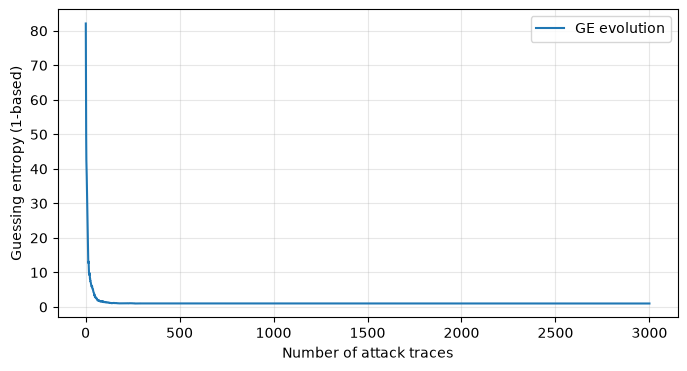

In [4]:
from sklearn.utils import shuffle
import numpy as np

num_attack_traces = 3000
runs = 50

def calculate_ge_nt(log_probabilities):
    # Map predicted class probabilities to the 256 key hypotheses.
    nonce0 = attack_data[:, 2]
    nonce1 = attack_data[:, 3]
    hypothesis_probabilities = np.zeros((n_attack, 256))

    for index in range(n_attack):
        for hypothesis in range(256):
            key1 = hypothesis

            if leakage_model == "SB-8":
              hypothesis_probabilities[index, hypothesis] = log_probabilities[
                  index, nonce0[index] ^ nonce1[index] ^ (IV[target_byte] & key1) ^ (nonce1[index] & key1) ^ key1]
            elif leakage_model == "HW":
              hypothesis_probabilities[index, hypothesis] = log_probabilities[
                  index, HW[nonce0[index] ^ nonce1[index] ^ (IV[target_byte] & key1) ^ (nonce1[index] & key1) ^ key1]]

    # Accumulate scores and average the correct-key rank over repeated attacks.
    key_ranking_sum = np.zeros(num_attack_traces)
    for run in range(runs):
        shuffled_probabilities = shuffle(hypothesis_probabilities, random_state=run)
        key_probabilities = np.zeros(256)

        for index in range(num_attack_traces):
            key_probabilities += shuffled_probabilities[index]
            key_probabilities_sorted = np.argsort(key_probabilities)[::-1]

            correct_key_rank = list(key_probabilities_sorted).index(good_key) + 1
            key_ranking_sum[index] += correct_key_rank

    ge = key_ranking_sum / runs

    nt = None

    for index in range(num_attack_traces):
        if ge[index] == 1:
            nt = index + 1
            break

    return ge, nt

import matplotlib.pyplot as plt

model_probabilities = model.predict(X_attack, batch_size=batch_size, verbose=1)

log_probabilities = np.log(model_probabilities.astype(np.float64) + 1e-40)
ge, nt = calculate_ge_nt(log_probabilities)
print(f'Final GE : {ge[-1]:.2f}')
print(f'NT for : {nt}')
trace_axis = np.arange(1, num_attack_traces + 1)
plt.figure(figsize=(8, 4))
plt.plot(trace_axis, ge, label=f'GE evolution')
plt.xlabel('Number of attack traces')
plt.ylabel('Guessing entropy (1-based)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Apply $L_1$ Regularization

In practice, $L_1$ regularization is usually introduced during **hyperparameter tuning**, where its regularization strength, $\lambda$, is tuned together with the other model hyperparameters.

Here, however, our goal is slightly different. Instead of searching for a new optimal model, we start from the same baseline architecture and add $L_1$ regularization to investigate **how it changes the attack performance**.

Several candidate values for $\lambda$ are provided. You can test them one by one to observe the effect of different regularization strengths.

### Exercise

Add $L_1$ regularization to the baseline model. Check the relevant Keras/TensorFlow documentation to determine how $L_1$ regularization should be added to the Dense layers.

Repeat the experiment for different values of the regularization strength, $\lambda$, and compare the attack performance with that of the baseline model.

For each value of $\lambda$:

- Train the model.
- Perform the attack.
- Report the **Guessing Entropy (GE)**.
- Report the **Number of attack Traces (NT)**.
- Compare the results with the baseline model.

**NOTE:** For a fair comparison, all model variants should start from the same initial conditions and use the same data split and training configuration.

A fixed random seed has already been provided for this purpose. **Do not change it.** This ensures that the observed differences are mainly caused by the regularization strength rather than by differences in weight initialization or data shuffling.

Training model with L1 regularization (lambda=1e-06)
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step
Final GE : 1.00
NT for : 273


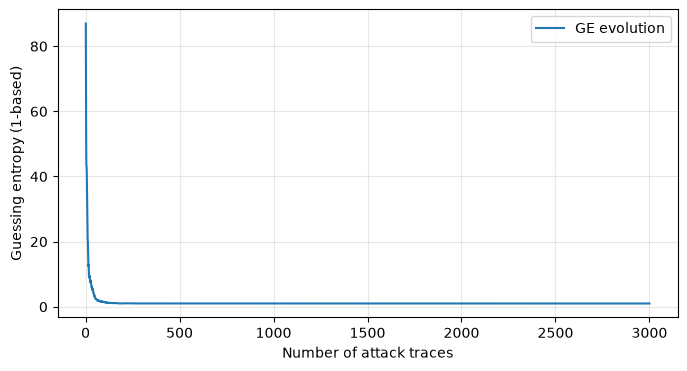

Training model with L1 regularization (lambda=0.0001)
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step
Final GE : 1.00
NT for : 85


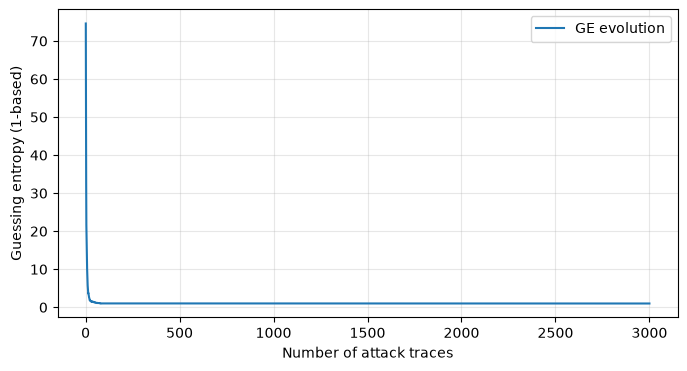

Training model with L1 regularization (lambda=0.1)
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step
Final GE : 158.64
NT for : None


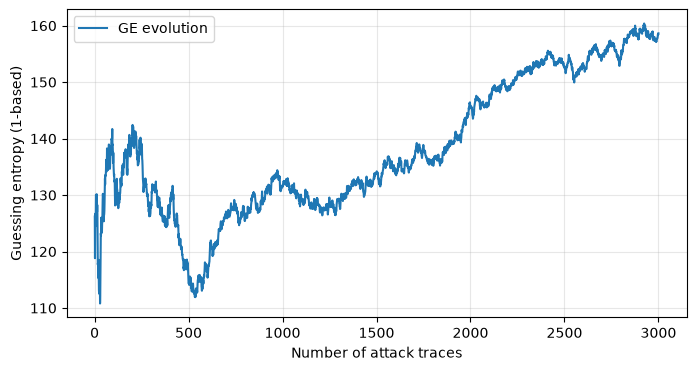

In [ ]:
#l1
Lambda= [1e-06, 0.0001, 0.1]


def create_model_l1(input_length, lambda_l1):
    tf.keras.utils.set_random_seed(929735)
    regularizer = tf.keras.regularizers.l1(lambda_l1)

    inputs = Input(shape=(input_length,))
    x = BatchNormalization()(inputs)

    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)

    outputs_layer = Dense(256, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs_layer)

    model.compile(
        optimizer=Adam(learning_rate=0.0009969971601608608),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


for L in Lambda:
    print(f"Training model with L1 regularization (lambda={L})")
    model_l1 = create_model_l1(X_profiling.shape[1], L)
    history_l1 = model_l1.fit(X_profiling, 
                        Y_profiling,
                        validation_split=0.15,
                        epochs=epochs, 
                        batch_size=batch_size, 
                        verbose=0)

    model_probabilities = model_l1.predict(X_attack, batch_size=batch_size, verbose=1)

    log_probabilities = np.log(model_probabilities.astype(np.float64) + 1e-40)
    ge, nt = calculate_ge_nt(log_probabilities)

    print(f'Final GE : {ge[-1]:.2f}')
    print(f'NT for : {nt}')
    trace_axis = np.arange(1, num_attack_traces + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(trace_axis, ge, label=f'GE evolution')
    plt.xlabel('Number of attack traces')
    plt.ylabel('Guessing entropy (1-based)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

del model
K.clear_session()
gc.collect()



## Apply $L_2$ Regularization

$L_2$ regularization is applied in a similar way to $L_1$ regularization, but it penalizes large weights differently and can therefore affect the model's behavior and attack performance in a different way.

### Exercise

Repeat the previous experiment using $L_2$ regularization.

Try different values of the regularization strength, $\lambda$, and compare the results with those obtained using:

- the baseline model,
- and the $L_1$-regularized model.

For each value of $\lambda$:

- Train the model.
- Perform the attack.
- Calculate the **Guessing Entropy (GE)**.
- Calculate the **Number of attack Traces (NT)**.
- Compare the attack performance with the baseline model.

As before, keep the same random seed, data split, and training configuration so that the comparison remains fair.


Training model with L2 regularization (lambda=1e-06)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Final GE : 1.00
NT for : 276


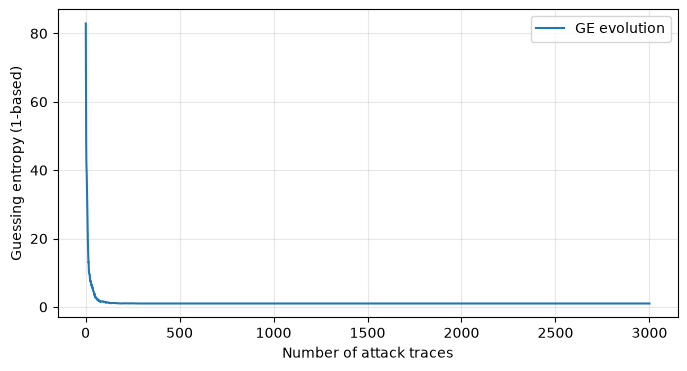

Training model with L2 regularization (lambda=0.01)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Final GE : 1.00
NT for : 96


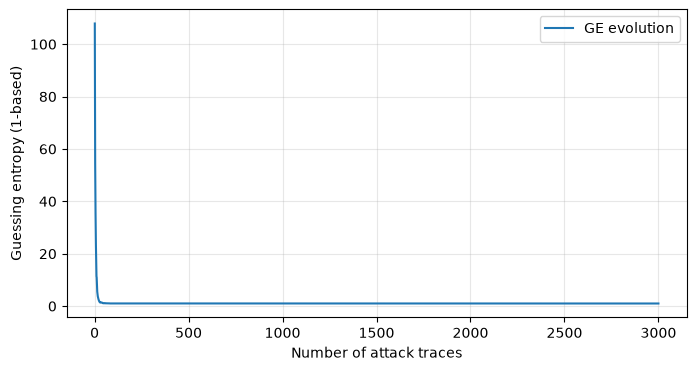

Training model with L2 regularization (lambda=0.1)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Final GE : 199.80
NT for : None


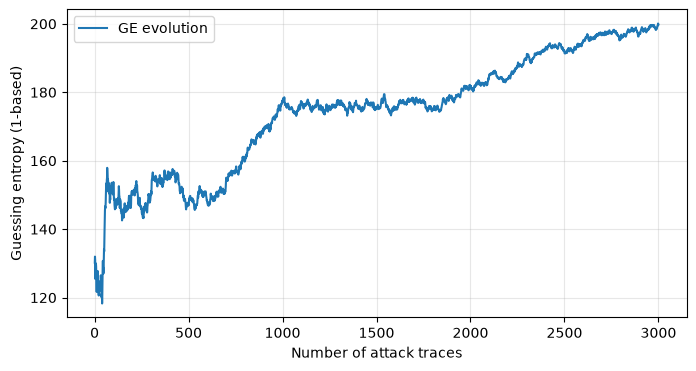

In [ ]:
#l2
Lambda= [1e-06, 0.01, 0.1]


def create_model_l2(input_length, lambda_l2):
    tf.keras.utils.set_random_seed(929735)
    regularizer = tf.keras.regularizers.l2(lambda_l2)

    inputs = Input(shape=(input_length,))
    x = BatchNormalization()(inputs)

    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform", kernel_regularizer=regularizer)(x)

    outputs_layer = Dense(256, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs_layer)

    model.compile(
        optimizer=Adam(learning_rate=0.0009969971601608608),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


for L in Lambda:
    print(f"Training model with L2 regularization (lambda={L})")
    model_l2 = create_model_l2(X_profiling.shape[1], L)
    history_l2 = model_l2.fit(X_profiling, 
                        Y_profiling,
                        validation_split=0.15,
                        epochs=epochs, 
                        batch_size=batch_size, 
                        verbose=0)

    model_probabilities = model_l2.predict(X_attack, batch_size=batch_size, verbose=1)

    log_probabilities = np.log(model_probabilities.astype(np.float64) + 1e-40)
    ge, nt = calculate_ge_nt(log_probabilities)

    print(f'Final GE : {ge[-1]:.2f}')
    print(f'NT for : {nt}')
    trace_axis = np.arange(1, num_attack_traces + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(trace_axis, ge, label=f'GE evolution')
    plt.xlabel('Number of attack traces')
    plt.ylabel('Guessing entropy (1-based)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show


del model
K.clear_session()
gc.collect()


## Apply Dropout Regularization

Dropout is another commonly used regularization technique. Instead of adding a penalty term to the loss function, Dropout randomly disables a fraction of neurons during training.

The dropout rate controls the fraction of neurons that are ignored in each training step. A small dropout rate introduces mild regularization, while a larger value applies stronger regularization.

### Exercise

Add Dropout layers to the baseline model and repeat the experiment using different dropout rates.

Try several dropout rates and compare the results with those obtained using:

- the baseline model,
- the $L_1$-regularized model,
- and the $L_2$-regularized model.

For each dropout rate:

- Train the model.
- Perform the attack.
- Calculate the **Guessing Entropy (GE)**.
- Calculate the **Number of attack Traces (NT)**.
- Compare the attack performance with the baseline model.

As in the previous experiments, keep the same random seed, data split, and training configuration so that the comparison remains fair.

Training model with Dropout (rate=0.1)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Final GE : 1.00
NT for : 374


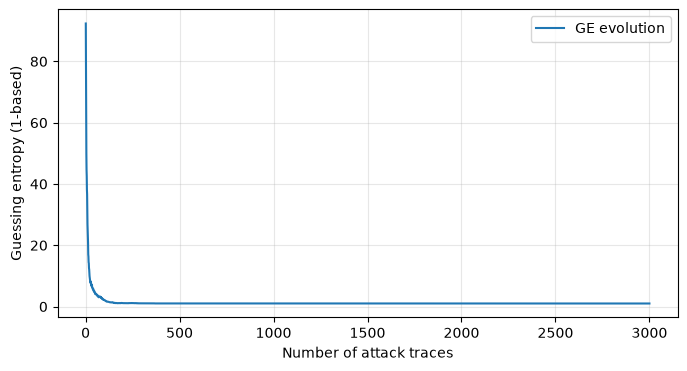

Training model with Dropout (rate=0.3)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Final GE : 1.00
NT for : 287


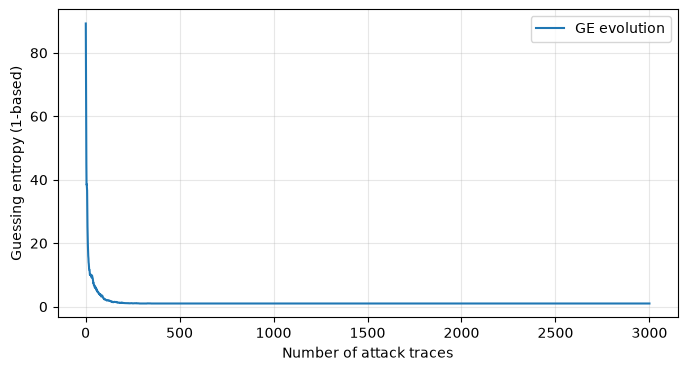

Training model with Dropout (rate=0.5)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Final GE : 1.00
NT for : 1516


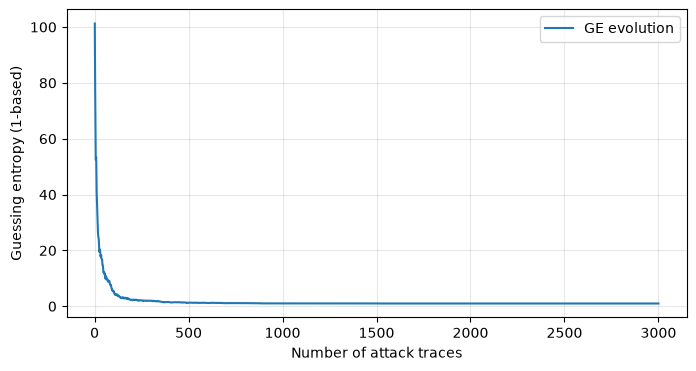

Training model with Dropout (rate=0.7)


I0000 00:00:1791465982.267721 1162920 se_gpu_pjrt_compiler.cc:274] Found GPU target config and a PjRtClient with matching configuration. Performing a JIT compilation.


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Final GE : 236.50
NT for : None


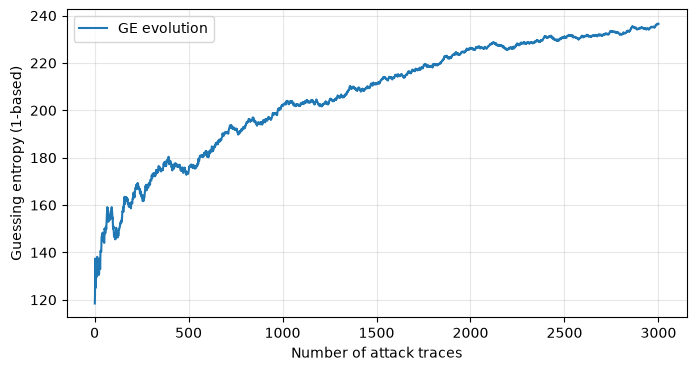

NameError: name 'model' is not defined

In [41]:
# Dropout
rate= [0.1, 0.3, 0.5, 0.7]

def create_model_dropout(input_length, dropout_rate):
    tf.keras.utils.set_random_seed(929735)
    inputs = Input(shape=(input_length,))
    x = BatchNormalization()(inputs)
    x = Dropout(rate=dropout_rate)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)
    x = Dropout(rate=dropout_rate)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)
    x = Dropout(rate=dropout_rate)(x)
    x = Dense(200, activation="elu", kernel_initializer="glorot_uniform")(x)
    outputs_layer = Dense(256, activation="softmax")(x)
    model = Model(inputs=inputs, outputs=outputs_layer)
    model.compile(
        optimizer=Adam(learning_rate=0.0009969971601608608),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

for r in rate:
    print(f"Training model with Dropout (rate={r})")
    model_dropout = create_model_dropout(X_profiling.shape[1], r)
    history_dropout = model_dropout.fit(X_profiling,
                        Y_profiling,
                        validation_split=0.15,
                        epochs=epochs,
                        batch_size=batch_size,
                        verbose=0)

    model_probabilities = model_dropout.predict(X_attack, batch_size=batch_size, verbose=1)

    log_probabilities = np.log(model_probabilities.astype(np.float64) + 1e-40)
    ge, nt = calculate_ge_nt(log_probabilities)

    print(f'Final GE : {ge[-1]:.2f}')
    print(f'NT for : {nt}')
    trace_axis = np.arange(1, num_attack_traces + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(trace_axis, ge, label=f'GE evolution')
    plt.xlabel('Number of attack traces')
    plt.ylabel('Guessing entropy (1-based)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

del model
K.clear_session()
gc.collect()


compare. 

should we generalize the observation here?
